In [1]:
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt

In [2]:
runs=['oper_01']

In [3]:
ht = xr.open_mfdataset([f'/jetfs/scratch/psplechtna/thesisdata/oper/2024/heighttest_{run}.nc' for run in runs])

In [4]:
ht

<xarray.Dataset> Size: 2kB
Dimensions:       (level: 7, pointspec: 24)
Coordinates:
  * level         (level) <U6 168B '50.0' '100.0' '200.0' ... '2000.0' 'bl'
    release_time  (pointspec) datetime64[ns] 192B dask.array<chunksize=(24,), meta=np.ndarray>
    number        int64 8B ...
Dimensions without coordinates: pointspec
Data variables:
    lh_per_rel    (level, pointspec) float32 672B dask.array<chunksize=(7, 24), meta=np.ndarray>
    sh_per_rel    (level, pointspec) float32 672B dask.array<chunksize=(7, 24), meta=np.ndarray>
Attributes: (12/32)
    GRIB_paramId:                             147
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      1038240
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            accum
    ...                                       ...
    GRIB_totalNumber:                         0
    GRIB_units:                               J m**-2
    standard_name:                            surface_upward_latent_heat_flux
    GRIB_surface:                             0.0
    decay:                                    -999.9000244140625
    weightmolar:                              29.0

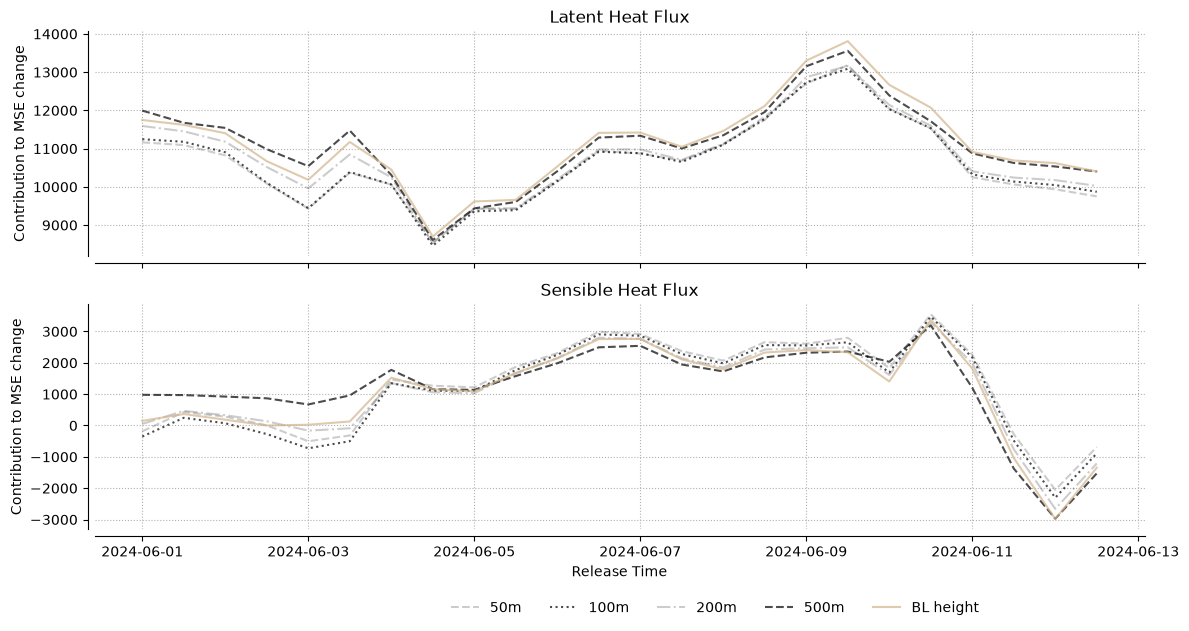

In [49]:
xes = ht['lh_per_rel'].release_time

fig, ax = plt.subplots(2, 1, figsize=(12,6), sharex=True)


ax[0].plot(xes, ht['lh_per_rel'].sel(level='50.0'), color='k', linestyle='--', alpha=0.2, label='50m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='100.0'), color='k', linestyle=':', alpha=0.7, label='100m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='200.0'), color='k', linestyle='-.', alpha=0.2, label='200m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='500.0'), color='k', linestyle='--', alpha=0.7, label='500m')
#ax[0].plot(xes, ht['lh_per_rel'].sel(level='1000.0'), color='k', linestyle=':', alpha=0.2, label='1000m')
#ax[0].plot(xes, ht['lh_per_rel'].sel(level='2000.0'), color='k', linestyle='-.', alpha=0.7, label='2000m')
ax[0].plot(xes, ht['lh_per_rel'].sel(level='bl'), color='tan', linestyle='-', alpha=0.7, label='BL height')

ax[0].set_title('Latent Heat Flux')

ax[1].plot(xes, ht['sh_per_rel'].sel(level='50.0'), color='k', linestyle='--', alpha=0.2)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='100.0'), color='k', linestyle=':', alpha=0.7)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='200.0'), color='k', linestyle='-.', alpha=0.2)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='500.0'), color='k', linestyle='--', alpha=0.7)
#ax[1].plot(xes, ht['sh_per_rel'].sel(level='1000.0'), color='k', linestyle=':', alpha=0.2)
#ax[1].plot(xes, ht['sh_per_rel'].sel(level='2000.0'), color='k', linestyle='-.', alpha=0.7)
ax[1].plot(xes, ht['sh_per_rel'].sel(level='bl'), color='tan', linestyle='-', alpha=0.7)

ax[1].set_xlabel('Release Time')
ax[1].set_title('Sensible Heat Flux')

for axs in ax:
    for spine in ['top', 'right']:
        axs.spines[spine].set_visible(False)
    spine_offset=5
    axs.spines.left.set_position(('outward', spine_offset))
    axs.spines.bottom.set_position(('outward', spine_offset))
    axs.grid(linestyle=':')
    axs.set_ylabel('Contribution to MSE change')

fig.legend(bbox_to_anchor=(0.83, 0.01), ncol=7, frameon=True, framealpha=1, edgecolor='white', fontsize=10)

fig.tight_layout()